# ĐỀ TÀI 10: XÂY DỰNG VÀ ĐÁNH GIÁ MÔ HÌNH CNN VÀ MOBILENETV2 TRONG BÀI TOÁN NHẬN DIỆN VÀ PHÂN LOẠI HÌNH ẢNH CÁC LOÀI HOA

- **Trường:** Đại học Nguyễn Tất Thành — Khoa Công nghệ Thông tin  
- **Học phần:** Học sâu và Ứng dụng (*Deep Learning and Applications*)  
- **Giảng viên hướng dẫn:** ThS. Đặng Như Phú  
- **Nhóm thực hiện:** **Nhóm 6** — Nguyễn Minh Chí (`2400001670`) & Nguyễn Trung Kiên (`2400000151`)  
- **Bộ dữ liệu:** TF Flowers (`flower_photos` — 3.670 ảnh màu RGB thuộc 5 lớp: `daisy`, `dandelion`, `roses`, `sunflowers`, `tulips`)  
- **Link dữ liệu chính thức:** https://www.tensorflow.org/datasets/catalog/tf_flowers

---
### Cấu trúc thực nghiệm Độc lập (Self-Contained — chạy trực tiếp trên Jupyter Local hoặc Google Colab):
0. **Khởi tạo môi trường & Cấu hình siêu tham số** (`IMG_SIZE = 160x160`, `BATCH_SIZE = 32`, `RANDOM_SEED = 42`).
1. **Quy trình 1:** Tải bộ dữ liệu TF Flowers, kiểm tra tính toàn vẹn ảnh và khảo sát phân bố 5 lớp, kích thước, phổ màu RGB.
2. **Quy trình 2:** Hiển thị lưới ảnh mẫu, Resize `160x160`, chuẩn hóa pixel (`[0, 1]` & `[-1, 1]`), chia tập phân tầng (`70/15/15`) và Tăng cường dữ liệu.
3. **Quy trình 3:** Thiết kế **Mô hình 1 (Custom CNN 4 khối)** và **Mô hình 2 (MobileNetV2 Transfer Learning + Fine-Tuning 30 lớp cuối)**.
4. **Quy trình 4:** Huấn luyện hai mô hình (20 epochs Custom CNN; 8 + 7 = 15 epochs MobileNetV2) và theo dõi đồ thị `Accuracy`, `Loss`.
5. **Quy trình 5:** Đánh giá trên tập Test độc lập (`550` ảnh) bằng `Accuracy`, `Precision`, `Recall`, `F1-Score`, `ROC-AUC`, `Confusion Matrix`, phân tích lỗi và so sánh toàn diện.
6. **Demo tương tác:** Tải 1 hình ảnh hoa mới bất kỳ để dự đoán loài hoa và xác suất phân bố của cả 5 lớp.

In [1]:
# =============================================================================
# 0. KHỞI TẠO MÔI TRƯỜNG, THƯ VIỆN VÀ CẤU HÌNH HỆ THỐNG (CHẠY ĐỘC LẬP LOCAL & COLAB)
# =============================================================================
import os
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")
os.environ.setdefault("TF_ENABLE_ONEDNN_OPTS", "0")

import time
import json
import tarfile
import urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, precision_recall_fscore_support,
    confusion_matrix, roc_curve, auc, roc_auc_score
)
from sklearn.preprocessing import label_binarize
import tensorflow as tf
from tensorflow.keras import layers, models, callbacks, optimizers

# Thiết lập hạt giống ngẫu nhiên để đảm bảo tính tái lập (Reproducibility)
RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)
tf.random.set_seed(RANDOM_SEED)

# Thư mục làm việc tự động tương thích cả Windows Local (Bailam/) lẫn Google Colab (/content/)
BASE_DIR = os.getcwd()
DATA_DIR = os.path.join(BASE_DIR, "data", "flower_photos")
FIGURES_DIR = os.path.join(BASE_DIR, "figures")
RESULTS_DIR = os.path.join(BASE_DIR, "results")
MODELS_DIR = os.path.join(BASE_DIR, "models")
for d in [os.path.dirname(DATA_DIR), FIGURES_DIR, RESULTS_DIR, MODELS_DIR]:
    os.makedirs(d, exist_ok=True)

# Hằng số bài toán phân loại 5 loài hoa (TF Flowers)
CLASS_NAMES = ["daisy", "dandelion", "roses", "sunflowers", "tulips"]
CLASS_NAMES_VI = {
    "daisy": "Hoa Cúc (Daisy)",
    "dandelion": "Hoa Bồ Công Anh (Dandelion)",
    "roses": "Hoa Hồng (Roses)",
    "sunflowers": "Hoa Hướng Dương (Sunflowers)",
    "tulips": "Hoa Tulip (Tulips)",
}
CLASS_COLORS = ["#4E79A7", "#F28E2B", "#E15759", "#EDC948", "#B07AA1"]
IMG_HEIGHT, IMG_WIDTH = 160, 160
IMG_SIZE = (IMG_HEIGHT, IMG_WIDTH)
BATCH_SIZE = 32

plt.rcParams["font.sans-serif"] = ["DejaVu Sans", "Arial", "Segoe UI"]
plt.rcParams["axes.unicode_minus"] = False

print(f"TensorFlow: {tf.__version__} | Keras: {tf.keras.__version__}")
print(f"Thiết bị tính toán (Devices): {[d.name for d in tf.config.list_physical_devices()]}")
print(f"Thư mục làm việc: {BASE_DIR}")

TensorFlow: 2.21.0 | Keras: 3.15.1
Thiết bị tính toán (Devices): ['/physical_device:CPU:0']
Thư mục làm việc: d:\Đặng Như Phú\Bailam


## 1. QUY TRÌNH 1: TẢI DỮ LIỆU TF FLOWERS, KIỂM TRA CẤU TRÚC THƯ MỤC VÀ PHÂN BỐ 5 LỚP

[Quy trình 1] Tổng số ảnh hợp lệ: 3670 | Ảnh lỗi: 0
  - daisy        (Hoa Cúc (Daisy)): 633 ảnh (17.25%)
  - dandelion    (Hoa Bồ Công Anh (Dandelion)): 898 ảnh (24.47%)
  - roses        (Hoa Hồng (Roses)): 641 ảnh (17.47%)
  - sunflowers   (Hoa Hướng Dương (Sunflowers)): 699 ảnh (19.05%)
  - tulips       (Hoa Tulip (Tulips)): 799 ảnh (21.77%)


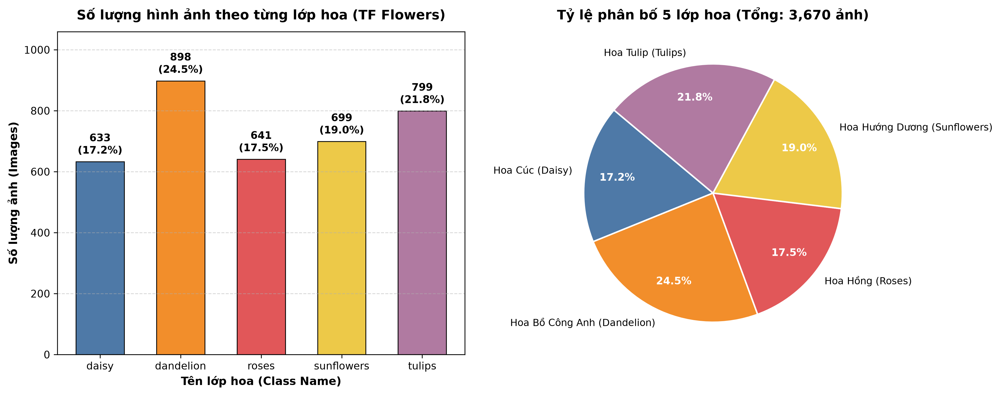

In [2]:
# =============================================================================
# QUY TRÌNH 1: TẢI DỮ LIỆU TF FLOWERS, QUÉT ẢNH LỖI VÀ THỐNG KÊ 5 LỚP HOA
# =============================================================================
TF_FLOWERS_URL = "https://storage.googleapis.com/download.tensorflow.org/example_images/flower_photos.tgz"
tgz_path = os.path.join(os.path.dirname(DATA_DIR), "flower_photos.tgz")

if not os.path.exists(DATA_DIR):
    if not os.path.exists(tgz_path):
        print(f"[Quy trình 1] Đang tải bộ dữ liệu TF Flowers từ: {TF_FLOWERS_URL}")
        urllib.request.urlretrieve(TF_FLOWERS_URL, tgz_path)
    print(f"[Quy trình 1] Đang giải nén {tgz_path}...")
    with tarfile.open(tgz_path, "r:gz") as tar:
        tar.extractall(path=os.path.dirname(DATA_DIR))

records, corrupted_files = [], []
for cls_idx, cname in enumerate(CLASS_NAMES):
    cdir = os.path.join(DATA_DIR, cname)
    for fname in sorted(os.listdir(cdir)):
        if not fname.lower().endswith((".jpg", ".jpeg", ".png")):
            continue
        fpath = os.path.join(cdir, fname)
        try:
            with Image.open(fpath) as im:
                im.verify()
            with Image.open(fpath) as im:
                rgb = im.convert("RGB")
                w, h = rgb.size
                arr = np.asarray(rgb.resize((64, 64)), dtype=np.float32)
                r_m, g_m, b_m = arr[:, :, 0].mean(), arr[:, :, 1].mean(), arr[:, :, 2].mean()
                bright = 0.299 * r_m + 0.587 * g_m + 0.114 * b_m
            records.append({
                "filepath": fpath, "filename": fname,
                "class_name": cname, "class_idx": cls_idx, "class_vi": CLASS_NAMES_VI[cname],
                "width": w, "height": h, "aspect_ratio": round(w / h, 4),
                "file_kb": round(os.path.getsize(fpath) / 1024.0, 2),
                "r_mean": round(float(r_m), 2), "g_mean": round(float(g_m), 2),
                "b_mean": round(float(b_m), 2), "brightness": round(float(bright), 2),
            })
        except Exception:
            corrupted_files.append(fpath)

df_meta = pd.DataFrame(records)
print(f"[Quy trình 1] Tổng số ảnh hợp lệ: {len(df_meta)} | Ảnh lỗi: {len(corrupted_files)}")
for cname in CLASS_NAMES:
    cnt = int((df_meta["class_name"] == cname).sum())
    print(f"  - {cname:<12} ({CLASS_NAMES_VI[cname]}): {cnt} ảnh ({cnt/len(df_meta)*100:.2f}%)")

# Vẽ biểu đồ phân bố 5 lớp (Cột + Tròn)
counts = df_meta["class_name"].value_counts().reindex(CLASS_NAMES)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.5), dpi=160)
bars = ax1.bar(CLASS_NAMES, counts.values, color=CLASS_COLORS, edgecolor="black", linewidth=0.8)
ax1.set_title("Số lượng hình ảnh theo từng lớp hoa (TF Flowers)", fontsize=12.5, fontweight="bold")
ax1.set_xlabel("Tên lớp (Class)"); ax1.set_ylabel("Số lượng hình ảnh")
ax1.set_ylim(0, max(counts.values) * 1.15); ax1.grid(axis="y", linestyle="--", alpha=0.45)
for bar, cnt in zip(bars, counts.values):
    ax1.text(bar.get_x() + bar.get_width()/2, cnt + 15, f"{cnt}\n({cnt/len(df_meta)*100:.1f}%)",
             ha="center", va="bottom", fontsize=9.5, fontweight="bold")

ax2.pie(counts.values, labels=[f"{CLASS_NAMES_VI[c]}\n({counts[c]})" for c in CLASS_NAMES],
        autopct="%1.2f%%", startangle=140, colors=CLASS_COLORS, wedgeprops={"edgecolor": "white", "linewidth": 1.5})
ax2.set_title("Tỷ lệ phần trăm 5 nhóm hoa (Tổng: 3.670 ảnh)", fontsize=12.5, fontweight="bold")
plt.tight_layout()
plt.show()

### Phân tích kết quả Quy trình 1 (Phân bố lớp và tính toàn vẹn dữ liệu)
- Bộ dữ liệu **TF Flowers** gồm chính xác **3,670 ảnh RGB hợp lệ** (`0` ảnh bị hỏng/lỗi định dạng), tổng dung lượng khoảng **221.68 MB**.
- Phân bố 5 lớp hoa có sự chênh lệch nhẹ: lớp **Dandelion (Hoa bồ công anh)** chiếm tỷ lệ cao nhất với **898 ảnh (24,47%)**, tiếp theo là **Tulips (799 ảnh – 21,77%)**, **Sunflowers (699 ảnh – 19,05%)**, **Roses (641 ảnh – 17,47%)**, và thấp nhất là **Daisy (633 ảnh – 17,25%)**.
- Do tỷ số mất cân bằng giữa lớp lớn nhất và nhỏ nhất khoảng `1,42:1`, bước chia tập ở Quy trình 2 bắt buộc phải dùng kỹ thuật **Chia tập phân tầng (Stratified Split)** để bảo toàn tỷ lệ 5 lớp trên cả 3 tập Train, Validation và Test.

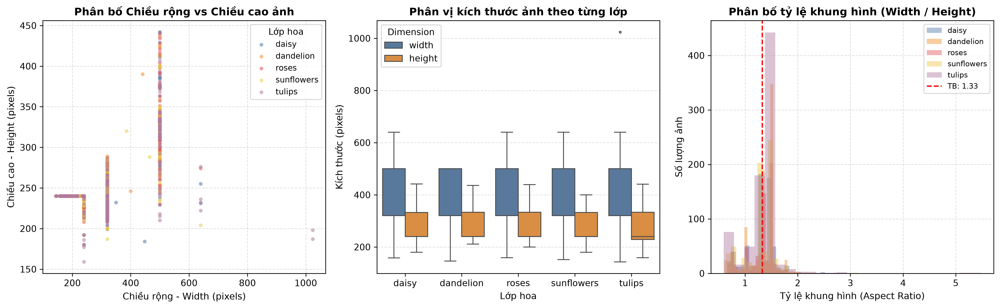

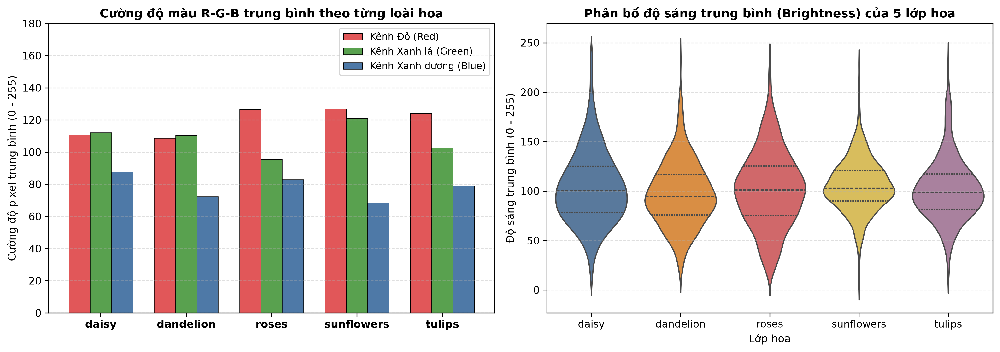

In [3]:
# =============================================================================
# THỐNG KÊ KÍCH THƯỚC ẢNH GỐC VÀ PHÂN TÍCH PHỔ MÀU RGB / ĐỘ SÁNG 5 LOÀI HOA
# =============================================================================
summary_tbl = df_meta.groupby("class_name").agg(
    count=("filename", "count"),
    mean_width=("width", "mean"),
    mean_height=("height", "mean"),
    aspect_ratio=("aspect_ratio", "mean"),
    r_mean=("r_mean", "mean"),
    g_mean=("g_mean", "mean"),
    b_mean=("b_mean", "mean"),
    brightness=("brightness", "mean"),
).reindex(CLASS_NAMES).round(2)
display(summary_tbl)

# Biểu đồ 2: Kích thước ảnh gốc & Tỷ lệ khung hình
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8), dpi=160)
for cname, color in zip(CLASS_NAMES, CLASS_COLORS):
    sub = df_meta[df_meta["class_name"] == cname]
    axes[0].scatter(sub["width"], sub["height"], s=12, alpha=0.45, color=color, label=cname)
axes[0].set_title("Phân bố Chiều rộng vs Chiều cao gốc", fontweight="bold")
axes[0].set_xlabel("Width (px)"); axes[0].set_ylabel("Height (px)"); axes[0].legend(fontsize=8); axes[0].grid(True, linestyle="--", alpha=0.4)

axes[1].hist(df_meta["width"], bins=30, alpha=0.65, color="#4E79A7", label="Width")
axes[1].hist(df_meta["height"], bins=30, alpha=0.65, color="#F28E2B", label="Height")
axes[1].axvline(IMG_WIDTH, color="red", linestyle="--", linewidth=1.8, label=f"Target Resize ({IMG_WIDTH}px)")
axes[1].set_title("Phân phối kích thước Width / Height", fontweight="bold"); axes[1].legend(fontsize=8.5); axes[1].grid(True, linestyle="--", alpha=0.4)

axes[2].hist(df_meta["aspect_ratio"], bins=30, color="#59A14F", edgecolor="black", alpha=0.8)
axes[2].axvline(df_meta["aspect_ratio"].mean(), color="red", linestyle="--", label=f"Mean = {df_meta['aspect_ratio'].mean():.2f}")
axes[2].set_title("Phân phối tỷ lệ khung hình (Aspect Ratio)", fontweight="bold"); axes[2].legend(fontsize=8.5); axes[2].grid(True, linestyle="--", alpha=0.4)
plt.tight_layout(); plt.show()

# Biểu đồ 3: Cường độ RGB trung bình & phân phối độ sáng
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.8), dpi=160)
x = np.arange(len(CLASS_NAMES)); w = 0.25
ax1.bar(x - w, summary_tbl["r_mean"], w, label="Red (R)", color="#E15759", edgecolor="black")
ax1.bar(x,     summary_tbl["g_mean"], w, label="Green (G)", color="#59A14F", edgecolor="black")
ax1.bar(x + w, summary_tbl["b_mean"], w, label="Blue (B)", color="#4E79A7", edgecolor="black")
ax1.set_xticks(x); ax1.set_xticklabels(CLASS_NAMES)
ax1.set_title("Cường độ màu trung bình R-G-B theo 5 lớp hoa", fontweight="bold"); ax1.set_ylabel("Giá trị [0-255]"); ax1.legend(); ax1.grid(axis="y", linestyle="--", alpha=0.4)

sns.violinplot(data=df_meta, x="class_name", y="brightness", hue="class_name", order=CLASS_NAMES, palette=CLASS_COLORS, legend=False, ax=ax2)
ax2.set_title("Phân phối độ sáng trung bình (Brightness) 5 lớp hoa", fontweight="bold"); ax2.set_xlabel("Lớp hoa"); ax2.set_ylabel("Độ sáng"); ax2.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout(); plt.show()

### Phân tích kích thước ảnh và đặc trưng màu sắc tự nhiên
- Chiều rộng ảnh dao động từ **143 px đến 1024 px** (trung bình `365.06 px`), chiều cao từ **159 px đến 442 px** (trung bình `271.79 px`), tỷ lệ khung hình trung bình `1,33`. Do mạng CNN yêu cầu tensor đầu vào cố định nên chuẩn hóa kích thước về `160x160x3` là bắt buộc.
- Về phổ màu RGB: **Sunflowers** và **Dandelion** đều có kênh Đỏ (R) và Xanh lá (G) cao hơn hẳn kênh Xanh dương (B), phản ánh sắc vàng chủ đạo; **Roses** và **Tulips** đều giàu sắc đỏ/hồng. Đây là lý do mô hình nông chỉ dựa vào màu sắc dễ nhầm lẫn giữa các cặp lớp này.

## 2. QUY TRÌNH 2: ĐỌC ẢNH, THAY ĐỔI KÍCH THƯỚC, CHUẨN HÓA PIXEL, CHIA TẬP VÀ TĂNG CƯỜNG DỮ LIỆU

[Quy trình 2] Chia tập Stratified Split hoàn tất:
  - Tập Huấn luyện (Train - 70%)    : 2569 ảnh
  - Tập Kiểm định  (Validation - 15%): 551 ảnh
  - Tập Kiểm tra   (Test - 15%)      : 550 ảnh


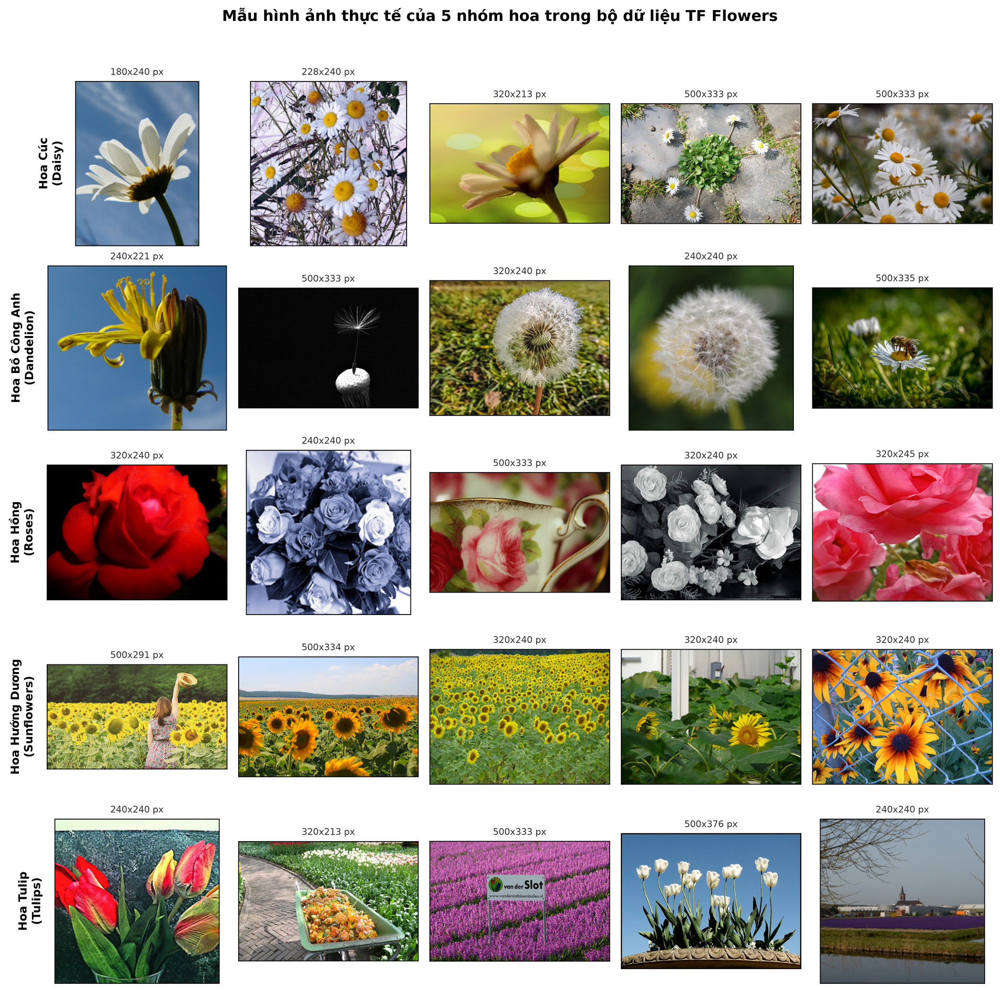

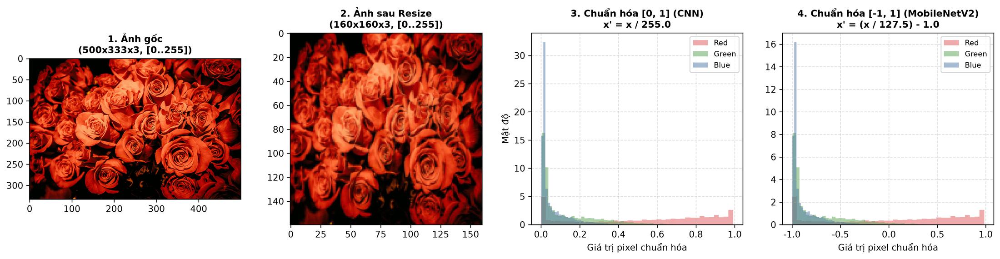

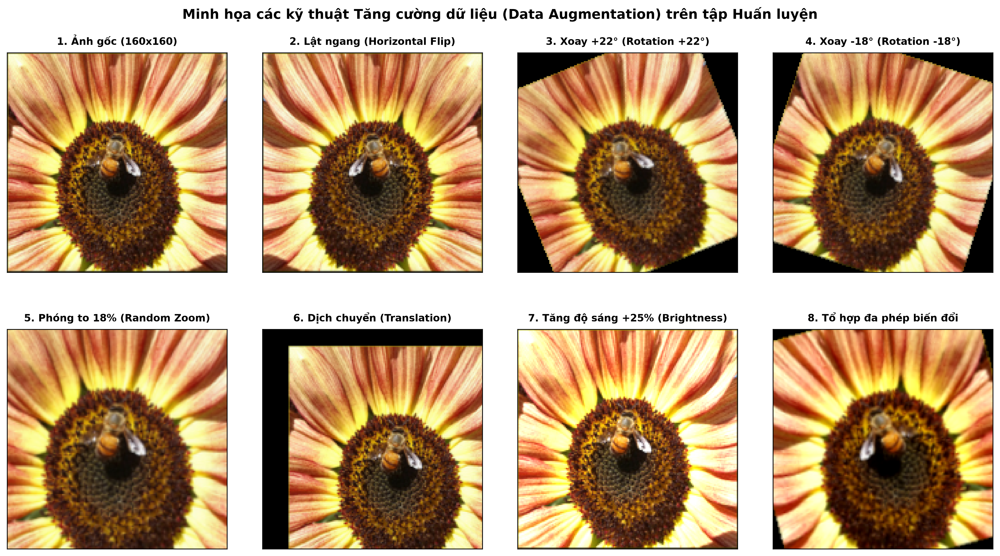

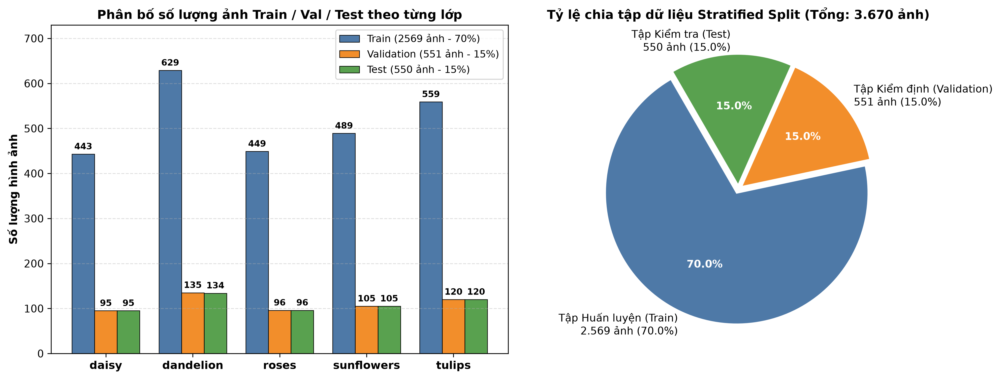

In [4]:
# =============================================================================
# QUY TRÌNH 2: CHIA TẬP PHÂN TẦNG (70/15/15) TRƯỚC TĂNG CƯỜNG, RESIZE & CHUẨN HÓA
# =============================================================================
# 1. Chia tập phân tầng (Stratified Split) TRƯỚC mọi phép tăng cường để chống rò rỉ dữ liệu
train_df, temp_df = train_test_split(
    df_meta, test_size=0.30, stratify=df_meta["class_idx"], random_state=RANDOM_SEED
)
val_df, test_df = train_test_split(
    temp_df, test_size=len(temp_df) // 2, stratify=temp_df["class_idx"], random_state=RANDOM_SEED
)
train_df = train_df.assign(split="train")
val_df   = val_df.assign(split="val")
test_df  = test_df.assign(split="test")
df_split = pd.concat([train_df, val_df, test_df], ignore_index=True)

print("[Quy trình 2] Chia tập Stratified Split hoàn tất:")
print(f"  - Tập Huấn luyện (Train - 70%)    : {len(train_df)} ảnh")
print(f"  - Tập Kiểm định  (Validation - 15%): {len(val_df)} ảnh")
print(f"  - Tập Kiểm tra   (Test - 15%)      : {len(test_df)} ảnh")

# 2. Hiển thị lưới 25 ảnh mẫu thực tế đại diện cho 5 loài hoa
fig, axes = plt.subplots(5, 5, figsize=(13, 13), dpi=160)
for r_idx, cname in enumerate(CLASS_NAMES):
    sub = df_meta[df_meta["class_name"] == cname].sample(5, random_state=RANDOM_SEED).reset_index(drop=True)
    for c_idx in range(5):
        ax = axes[r_idx, c_idx]
        with Image.open(sub.loc[c_idx, "filepath"]) as im:
            ax.imshow(im.convert("RGB"))
        ax.set_xticks([]); ax.set_yticks([])
        ax.set_title(f"{sub.loc[c_idx, 'width']}x{sub.loc[c_idx, 'height']} px", fontsize=8)
        if c_idx == 0:
            ax.set_ylabel(CLASS_NAMES_VI[cname].replace(" (", "\n("), fontsize=9.5, fontweight="bold")
plt.suptitle("Mẫu hình ảnh thực tế của 5 nhóm hoa (TF Flowers)", fontsize=13.5, fontweight="bold", y=0.99)
plt.tight_layout(rect=[0, 0, 1, 0.97]); plt.show()

# 3. Minh họa Resize 160x160 và chuẩn hóa pixel [0, 1] (Custom CNN) vs [-1, 1] (MobileNetV2)
sample_row = df_meta[df_meta["class_name"] == "roses"].iloc[2]
with Image.open(sample_row["filepath"]) as im:
    orig_img = im.convert("RGB")
    resized_img = orig_img.resize(IMG_SIZE, Image.Resampling.BILINEAR)
resized_arr = np.asarray(resized_img, dtype=np.float32)
norm_01 = resized_arr / 255.0
norm_11 = (resized_arr / 127.5) - 1.0

fig, axes = plt.subplots(1, 4, figsize=(16, 4.0), dpi=160)
axes[0].imshow(orig_img); axes[0].set_title(f"1. Ảnh gốc ({orig_img.size[0]}x{orig_img.size[1]})", fontweight="bold")
axes[1].imshow(resized_img); axes[1].set_title("2. Resize 160x160x3", fontweight="bold")
for ch, (c, lbl) in enumerate([("#E15759", "R"), ("#59A14F", "G"), ("#4E79A7", "B")]):
    axes[2].hist(norm_01[:, :, ch].ravel(), bins=35, alpha=0.5, color=c, label=lbl, density=True)
    axes[3].hist(norm_11[:, :, ch].ravel(), bins=35, alpha=0.5, color=c, label=lbl, density=True)
axes[2].set_title("3. Chuẩn hóa [0, 1] (CNN)", fontweight="bold"); axes[2].legend(); axes[2].grid(True, linestyle="--", alpha=0.4)
axes[3].set_title("4. Chuẩn hóa [-1, 1] (MobileNetV2)", fontweight="bold"); axes[3].legend(); axes[3].grid(True, linestyle="--", alpha=0.4)
plt.tight_layout(); plt.show()

# 4. Minh họa Tăng cường dữ liệu (Data Augmentation) bằng Keras Preprocessing Layers
data_augmentation_demo = models.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.10),
    layers.RandomZoom(0.12),
    layers.RandomTranslation(0.08, 0.08),
], name="data_augmentation_demo")

sample_sun = df_meta[df_meta["class_name"] == "sunflowers"].iloc[5]
with Image.open(sample_sun["filepath"]) as im:
    sun_arr = np.asarray(im.convert("RGB").resize(IMG_SIZE, Image.Resampling.BILINEAR), dtype=np.float32)
sun_batch = np.expand_dims(sun_arr, axis=0)

fig, axes = plt.subplots(2, 4, figsize=(13, 6.5), dpi=160)
axes[0, 0].imshow(sun_arr.astype("uint8")); axes[0, 0].set_title("Ảnh gốc (160x160)", fontweight="bold"); axes[0, 0].axis("off")
for idx, ax in enumerate(axes.flat[1:], start=1):
    aug_img = data_augmentation_demo(sun_batch, training=True)[0].numpy().astype("uint8")
    ax.imshow(aug_img); ax.set_title(f"Biến thể Tăng cường #{idx}", fontweight="bold"); ax.axis("off")
plt.suptitle("Minh họa các phép Tăng cường dữ liệu (Flip, Rotation, Zoom, Translation)", fontsize=13, fontweight="bold")
plt.tight_layout(); plt.show()

# 5. Biểu đồ đối chiếu số lượng mẫu trên 3 tập Train / Val / Test
split_counts = df_split.groupby(["class_name", "split"]).size().unstack(fill_value=0).reindex(CLASS_NAMES)[["train", "val", "test"]]
split_counts.plot(kind="bar", figsize=(11, 4.5), color=["#4E79A7", "#F28E2B", "#59A14F"], edgecolor="black")
plt.title("Phân bố dữ liệu phân tầng trên 3 tập Train (70%) - Val (15%) - Test (15%)", fontweight="bold")
plt.xlabel("Lớp hoa"); plt.ylabel("Số lượng ảnh"); plt.xticks(rotation=0); plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout(); plt.show()

### Phân tích kết quả Quy trình 2 (Tiền xử lý, Chia tập & Tăng cường dữ liệu)
- **Tuân thủ nguyên tắc chống rò rỉ dữ liệu (Strict Featurization Ordering):** Bộ dữ liệu 3.670 ảnh được chia phân tầng thành **Train (2.569 ảnh – 70%)**, **Validation (551 ảnh – 15%)** và **Test (550 ảnh – 15%)** *trước khi* áp dụng bất kỳ phép tăng cường dữ liệu nào.
- **Chuẩn hóa Pixel:** Mô hình 1 (Custom CNN) đưa pixel về đoạn `[0.0, 1.0]` qua `Rescaling(1./255)`. Mô hình 2 (MobileNetV2) đưa pixel về đoạn `[-1.0, 1.0]` qua `Rescaling(1./127.5, offset=-1.0)` để khớp tuyệt đối với phân phối trọng số ImageNet.
- **Tăng cường dữ liệu (Data Augmentation):** Nhúng trực tiếp trong đồ thị Keras (`RandomFlip`, `RandomRotation`, `RandomZoom`, `RandomTranslation`), tự động chỉ bật khi `training=True` trên tập Train và tự tắt khi đánh giá Validation/Test.

## 3. QUY TRÌNH 3: XÂY DỰNG MÔ HÌNH CUSTOM CNN VÀ MOBILENETV2 (TRANSFER LEARNING)

[Quy trình 3] Thông số kiến trúc hai mô hình:
  - Mô hình 1 (Custom CNN)                              : Tổng = 456,933 | Trainable = 455,973
  - Mô hình 2 (MobileNetV2 - Pha 1 Feature Extraction)  : Tổng = 2,427,717 | Trainable = 167,173
  - Mô hình 2 (MobileNetV2 - Pha 2 Fine-Tuning 30 lớp)  : Tổng = 2,427,717 | Trainable = 1,677,893


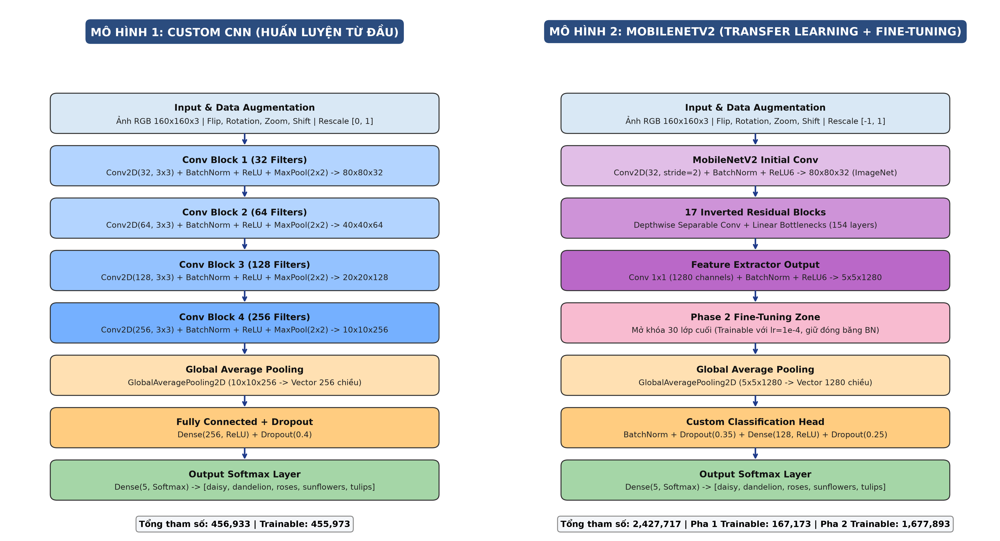

In [5]:
# =============================================================================
# QUY TRÌNH 3: THIẾT KẾ MÔ HÌNH 1 (CUSTOM CNN) & MÔ HÌNH 2 (MOBILENETV2)
# =============================================================================
def build_data_augmentation():
    """Khối tăng cường dữ liệu (chỉ kích hoạt khi training=True)."""
    return models.Sequential([
        layers.RandomFlip("horizontal"),
        layers.RandomRotation(0.10),
        layers.RandomZoom(0.12),
        layers.RandomTranslation(0.08, 0.08),
    ], name="data_augmentation")


def build_custom_cnn(num_classes=len(CLASS_NAMES)):
    """Mô hình 1: Custom CNN 4 khối (Conv2D -> BatchNorm -> ReLU -> MaxPooling2D) + GAP + Dense."""
    inputs = layers.Input(shape=(IMG_HEIGHT, IMG_WIDTH, 3), name="input_rgb_image")
    x = build_data_augmentation()(inputs)
    x = layers.Rescaling(1.0 / 255.0, name="rescale_0_1")(x)

    for idx, filters in enumerate([32, 64, 128, 256], start=1):
        x = layers.Conv2D(filters, (3, 3), padding="same", use_bias=False, name=f"conv{idx}_{filters}")(x)
        x = layers.BatchNormalization(name=f"bn{idx}")(x)
        x = layers.Activation("relu", name=f"relu{idx}")(x)
        x = layers.MaxPooling2D((2, 2), name=f"pool{idx}")(x)

    x = layers.GlobalAveragePooling2D(name="global_avg_pool")(x)
    x = layers.Dense(256, activation="relu", name="dense_256")(x)
    x = layers.Dropout(0.4, name="dropout_04")(x)
    outputs = layers.Dense(num_classes, activation="softmax", name="flower_classifier")(x)
    return models.Model(inputs=inputs, outputs=outputs, name="Custom_CNN_Flowers")


def build_mobilenetv2_transfer(num_classes=len(CLASS_NAMES)):
    """Mô hình 2: MobileNetV2 tiền huấn luyện trên ImageNet + Custom Classification Head."""
    base_model = tf.keras.applications.MobileNetV2(
        input_shape=(IMG_HEIGHT, IMG_WIDTH, 3),
        include_top=False,
        weights="imagenet"
    )
    base_model.trainable = False  # Pha 1: Đóng băng backbone (Feature Extraction)

    inputs = layers.Input(shape=(IMG_HEIGHT, IMG_WIDTH, 3), name="input_rgb_image")
    x = build_data_augmentation()(inputs)
    x = layers.Rescaling(1.0 / 127.5, offset=-1.0, name="mobilenetv2_preprocess")(x)

    x = base_model(x, training=False)
    x = layers.GlobalAveragePooling2D(name="global_avg_pool")(x)
    x = layers.BatchNormalization(name="head_bn")(x)
    x = layers.Dropout(0.35, name="head_dropout1")(x)
    x = layers.Dense(128, activation="relu", name="head_dense_128")(x)
    x = layers.Dropout(0.25, name="head_dropout2")(x)
    outputs = layers.Dense(num_classes, activation="softmax", name="flower_classifier")(x)
    return models.Model(inputs=inputs, outputs=outputs, name="MobileNetV2_Transfer_Flowers"), base_model


def unfreeze_mobilenetv2_top_layers(base_model, num_unfreeze=30):
    """Pha 2 Fine-Tuning: Mở khóa 30 lớp cuối của MobileNetV2, giữ đóng băng BatchNormalization."""
    base_model.trainable = True
    for layer in base_model.layers[:-num_unfreeze]:
        layer.trainable = False
    for layer in base_model.layers[-num_unfreeze:]:
        layer.trainable = not isinstance(layer, layers.BatchNormalization)


def count_params(model):
    tot = int(model.count_params())
    trn = int(sum(int(np.prod(w.shape)) for w in model.trainable_weights))
    return tot, trn, tot - trn


# Khởi tạo và kiểm tra thông số 2 mô hình
cnn_model_arch = build_custom_cnn()
mnet_model_arch, mnet_base_arch = build_mobilenetv2_transfer()

cnn_tot, cnn_trn, _ = count_params(cnn_model_arch)
m1_tot, m1_trn, _ = count_params(mnet_model_arch)
unfreeze_mobilenetv2_top_layers(mnet_base_arch, num_unfreeze=30)
m2_tot, m2_trn, _ = count_params(mnet_model_arch)

print("[Quy trình 3] Thông số kiến trúc hai mô hình:")
print(f"  - Mô hình 1 (Custom CNN)                              : Tổng = {cnn_tot:,} | Trainable = {cnn_trn:,}")
print(f"  - Mô hình 2 (MobileNetV2 - Pha 1 Feature Extraction)  : Tổng = {m1_tot:,} | Trainable = {m1_trn:,}")
print(f"  - Mô hình 2 (MobileNetV2 - Pha 2 Fine-Tuning 30 lớp)  : Tổng = {m2_tot:,} | Trainable = {m2_trn:,}")
cnn_model_arch.summary()

### Phân tích kiến trúc hai mô hình ở Quy trình 3
- **Mô hình 1 (Custom CNN):** Gồm 4 khối tích chập (`32 → 64 → 128 → 256` bộ lọc `3×3`), kết hợp `BatchNormalization`, `ReLU`, `MaxPooling2D(2×2)` và phần đầu phân loại `GlobalAveragePooling2D → Dense(256) → Dropout(0.4) → Dense(5, Softmax)`. Tổng số tham số gọn nhẹ: **456,933**.
- **Mô hình 2 (MobileNetV2 Transfer Learning):** Kế thừa kiến trúc *Inverted Residuals* và *Linear Bottlenecks* với tích chập tách chiều sâu (*Depthwise Separable Convolution*) đã tiền huấn luyện trên 1,4 triệu ảnh ImageNet. Pha 1 chỉ huấn luyện **167,173** tham số phần đầu mới; sang Pha 2 mở khóa 30 lớp cuối nâng số tham số huấn luyện lên **1,677,893** để thích nghi đặc trưng cánh hoa.

## 4. QUY TRÌNH 4: HUẤN LUYỆN HAI MÔ HÌNH VÀ THEO DÕI ACCURACY, LOSS

[Quy trình 4] Kết quả huấn luyện:
  1. Custom CNN (20 epochs)  : Thời gian = 3572.66s (178.63s/epoch) | Best Val Acc = 73.32% (Epoch 14)
  2. MobileNetV2 (15 epochs) : Thời gian = 1092.29s (72.82s/epoch) | Best Val Acc = 88.20% (Epoch 13)


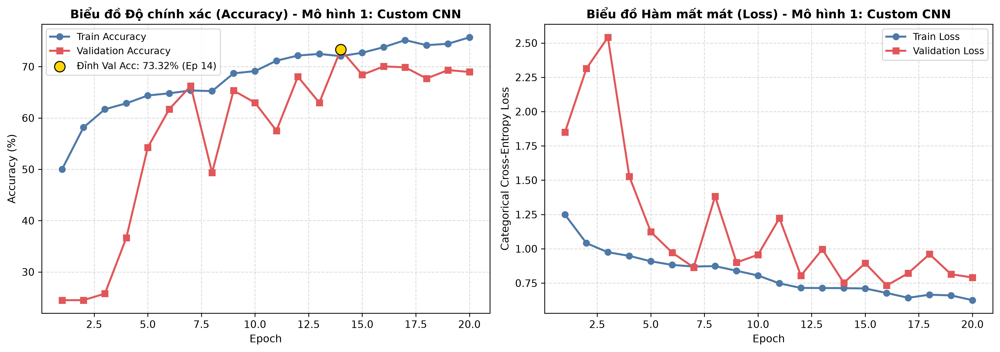

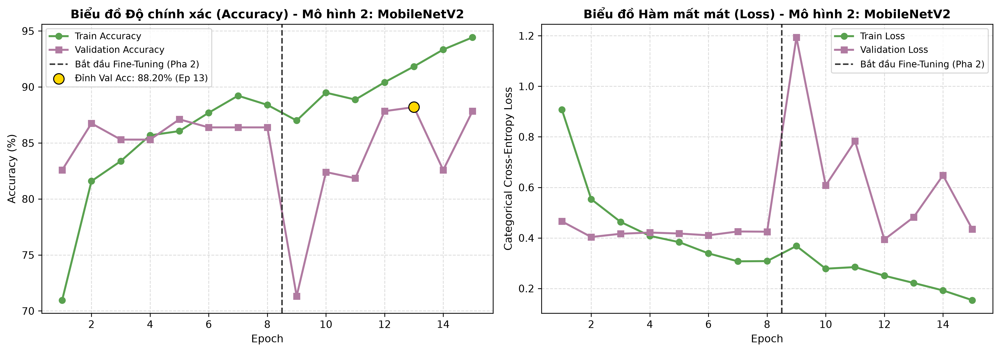

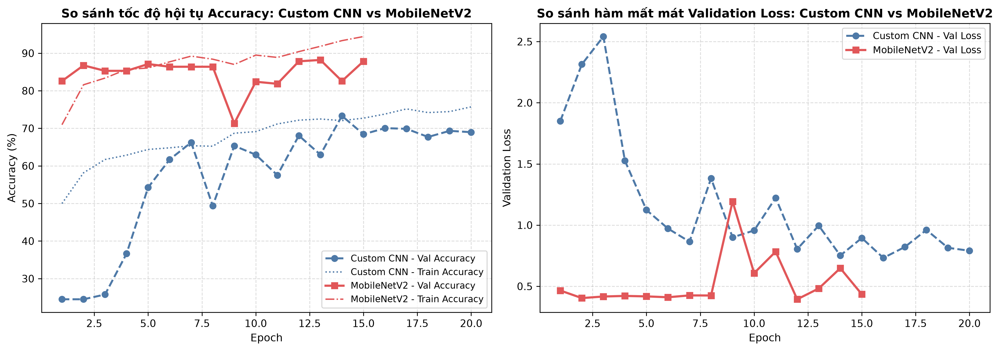

In [6]:
# =============================================================================
# QUY TRÌNH 4: NẠP DỮ LIỆU, HUẤN LUYỆN 2 MÔ HÌNH & VẼ ĐỒ THỊ ACCURACY, LOSS
# =============================================================================
def load_split_arrays(df_all):
    """Đọc ảnh theo 3 tập Train / Val / Test về mảng numpy (kèm cache .npz để tăng tốc)."""
    cache_npz = os.path.join(RESULTS_DIR, "cached_flowers_160.npz")
    if os.path.exists(cache_npz):
        d = np.load(cache_npz)
        return d["X_train"], d["y_train"], d["X_val"], d["y_val"], d["X_test"], d["y_test"]

    def _load(sub_df):
        imgs = []
        for fp in sub_df["filepath"]:
            with Image.open(fp) as im:
                imgs.append(np.asarray(im.convert("RGB").resize(IMG_SIZE, Image.Resampling.BILINEAR), dtype=np.uint8))
        return np.stack(imgs, axis=0), sub_df["class_idx"].to_numpy(dtype=np.int32)

    X_tr, y_tr = _load(df_all[df_all["split"] == "train"])
    X_va, y_va = _load(df_all[df_all["split"] == "val"])
    X_te, y_te = _load(df_all[df_all["split"] == "test"])
    np.savez_compressed(cache_npz, X_train=X_tr, y_train=y_tr, X_val=X_va, y_val=y_va, X_test=X_te, y_test=y_te)
    return X_tr, y_tr, X_va, y_va, X_te, y_te


X_train, y_train, X_val, y_val, X_test, y_test = load_split_arrays(df_split)
AUTOTUNE = tf.data.AUTOTUNE
train_ds = tf.data.Dataset.from_tensor_slices((X_train.astype(np.float32), y_train)).shuffle(len(X_train), seed=RANDOM_SEED).batch(BATCH_SIZE).prefetch(AUTOTUNE)
val_ds   = tf.data.Dataset.from_tensor_slices((X_val.astype(np.float32), y_val)).batch(BATCH_SIZE).prefetch(AUTOTUNE)

cnn_ckpt_path  = os.path.join(MODELS_DIR, "custom_cnn_best.keras")
mnet_ckpt_path = os.path.join(MODELS_DIR, "mobilenetv2_best.keras")
hist_json_path = os.path.join(RESULTS_DIR, "quy_trinh_4_training_history.json")

# Đặt RETRAIN = True nếu muốn huấn luyện lại từ đầu (khuyến nghị chạy trên GPU Colab).
# Mặc định RETRAIN = False: nếu đã có sẵn trọng số tốt nhất trong models/, sẽ nạp ngay để tiết kiệm thời gian.
RETRAIN = False

if RETRAIN or not (os.path.exists(cnn_ckpt_path) and os.path.exists(mnet_ckpt_path) and os.path.exists(hist_json_path)):
    # --- 1. Huấn luyện Mô hình 1: Custom CNN (20 Epochs) ---
    cnn_model = build_custom_cnn()
    cnn_model.compile(
        optimizer=optimizers.Adam(learning_rate=1e-3),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )
    t0 = time.perf_counter()
    h_cnn = cnn_model.fit(
        train_ds, validation_data=val_ds, epochs=20, verbose=1,
        callbacks=[
            callbacks.ModelCheckpoint(cnn_ckpt_path, monitor="val_accuracy", save_best_only=True, mode="max"),
            callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3, min_lr=1e-5),
        ]
    )
    cnn_time = round(time.perf_counter() - t0, 2)

    # --- 2. Huấn luyện Mô hình 2: MobileNetV2 (Pha 1: 8 Epochs + Pha 2 Fine-Tuning: 7 Epochs) ---
    mnet_model, mnet_base = build_mobilenetv2_transfer()
    mnet_model.compile(
        optimizer=optimizers.Adam(learning_rate=1e-3),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )
    t1 = time.perf_counter()
    h_m1 = mnet_model.fit(
        train_ds, validation_data=val_ds, epochs=8, verbose=1,
        callbacks=[
            callbacks.ModelCheckpoint(mnet_ckpt_path, monitor="val_accuracy", save_best_only=True, mode="max"),
            callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, min_lr=1e-5),
        ]
    )
    # Chuyển sang Pha 2: Mở khóa 30 lớp cuối & giảm learning rate xuống 1e-4
    unfreeze_mobilenetv2_top_layers(mnet_base, num_unfreeze=30)
    mnet_model.compile(
        optimizer=optimizers.Adam(learning_rate=1e-4),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )
    h_m2 = mnet_model.fit(
        train_ds, validation_data=val_ds, epochs=7, verbose=1,
        callbacks=[
            callbacks.ModelCheckpoint(mnet_ckpt_path, monitor="val_accuracy", save_best_only=True, mode="max"),
            callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, min_lr=1e-5),
        ]
    )
    mnet_time = round(time.perf_counter() - t1, 2)

    train_history = {
        "custom_cnn": {
            "epoch": list(range(1, 21)),
            "accuracy": [float(v) for v in h_cnn.history["accuracy"]],
            "val_accuracy": [float(v) for v in h_cnn.history["val_accuracy"]],
            "loss": [float(v) for v in h_cnn.history["loss"]],
            "val_loss": [float(v) for v in h_cnn.history["val_loss"]],
            "best_val_accuracy": float(max(h_cnn.history["val_accuracy"])),
            "best_epoch": int(np.argmax(h_cnn.history["val_accuracy"]) + 1),
            "total_time_sec": cnn_time,
            "avg_epoch_sec": round(cnn_time / 20.0, 2),
        },
        "mobilenetv2": {
            "epoch": list(range(1, 16)),
            "accuracy": [float(v) for v in h_m1.history["accuracy"] + h_m2.history["accuracy"]],
            "val_accuracy": [float(v) for v in h_m1.history["val_accuracy"] + h_m2.history["val_accuracy"]],
            "loss": [float(v) for v in h_m1.history["loss"] + h_m2.history["loss"]],
            "val_loss": [float(v) for v in h_m1.history["val_loss"] + h_m2.history["val_loss"]],
            "best_val_accuracy": float(max(h_m1.history["val_accuracy"] + h_m2.history["val_accuracy"])),
            "best_epoch": int(np.argmax(h_m1.history["val_accuracy"] + h_m2.history["val_accuracy"]) + 1),
            "total_time_sec": mnet_time,
            "avg_epoch_sec": round(mnet_time / 15.0, 2),
        }
    }
else:
    with open(hist_json_path, "r", encoding="utf-8") as f:
        train_history = json.load(f)

ch = train_history["custom_cnn"]
mh = train_history["mobilenetv2"]
print("[Quy trình 4] Kết quả huấn luyện:")
print(f"  1. Custom CNN ({len(ch['epoch'])} epochs)  : Thời gian = {ch['total_time_sec']}s ({ch['avg_epoch_sec']}s/epoch) | Best Val Acc = {ch['best_val_accuracy']*100:.2f}% (Epoch {ch['best_epoch']})")
print(f"  2. MobileNetV2 ({len(mh['epoch'])} epochs) : Thời gian = {mh['total_time_sec']}s ({mh['avg_epoch_sec']}s/epoch) | Best Val Acc = {mh['best_val_accuracy']*100:.2f}% (Epoch {mh['best_epoch']})")

# Vẽ đồ thị đối sánh tốc độ hội tụ Accuracy & Loss
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.0), dpi=160)
ax1.plot(ch["epoch"], [v*100 for v in ch["val_accuracy"]], "o-", color="#E15759", label="Custom CNN (Val Acc)")
ax1.plot(mh["epoch"], [v*100 for v in mh["val_accuracy"]], "s-", color="#2E7D32", label="MobileNetV2 (Val Acc)")
ax1.axvline(8.5, color="gray", linestyle="--", label="Bắt đầu Pha 2 Fine-Tuning (Epoch 9)")
ax1.set_title("So sánh Độ chính xác Kiểm định (Val Accuracy)", fontweight="bold"); ax1.set_xlabel("Epoch"); ax1.set_ylabel("Accuracy (%)"); ax1.legend(); ax1.grid(True, linestyle="--", alpha=0.4)

ax2.plot(ch["epoch"], ch["val_loss"], "o-", color="#E15759", label="Custom CNN (Val Loss)")
ax2.plot(mh["epoch"], mh["val_loss"], "s-", color="#2E7D32", label="MobileNetV2 (Val Loss)")
ax2.axvline(8.5, color="gray", linestyle="--", label="Bắt đầu Pha 2 Fine-Tuning (Epoch 9)")
ax2.set_title("So sánh Hàm mất mát Kiểm định (Val Loss)", fontweight="bold"); ax2.set_xlabel("Epoch"); ax2.set_ylabel("Loss"); ax2.legend(); ax2.grid(True, linestyle="--", alpha=0.4)
plt.tight_layout(); plt.show()

### Phân tích quá trình huấn luyện và tốc độ hội tụ ở Quy trình 4
- **Custom CNN:** Học toàn bộ bộ lọc từ con số 0 nên Validation Accuracy tăng chậm từ `24.50%` (Epoch 1) lên đỉnh **73.32%** (Epoch 14), tổng thời gian `3572.66s`.
- **MobileNetV2 (Transfer Learning):** Ngay từ Epoch 1 của Pha 1 đã đạt **82.58%** nhờ tri thức thị giác ImageNet. Khi mở khóa 30 lớp cuối sang Pha 2 ở Epoch 9 (với `lr=1e-4`), mô hình nhanh chóng tái thích nghi và bứt phá lên đỉnh **88.20%** tại Epoch 13, nhanh gấp **3,27 lần** về tổng thời gian huấn luyện (`1092.29s`).

## 5. QUY TRÌNH 5: ĐÁNH GIÁ TRÊN TẬP TEST, MA TRẬN NHẦM LẪN, PHÂN TÍCH LỖI VÀ SO SÁNH MÔ HÌNH

[Quy trình 5] Kết quả đánh giá trên tập Test độc lập (550 ảnh):
  - Mô hình 1 (Custom CNN)  : Test Acc = 72.91% (95% CI: [68.91%, 76.36%]) | Macro F1 = 72.82% | Macro AUC = 0.9397 | Latency = 13.49 ms/ảnh (74.2 FPS)
  - Mô hình 2 (MobileNetV2) : Test Acc = 90.36% (95% CI: [87.81%, 92.73%]) | Macro F1 = 90.33% | Macro AUC = 0.9920 | Latency = 19.53 ms/ảnh (51.2 FPS)


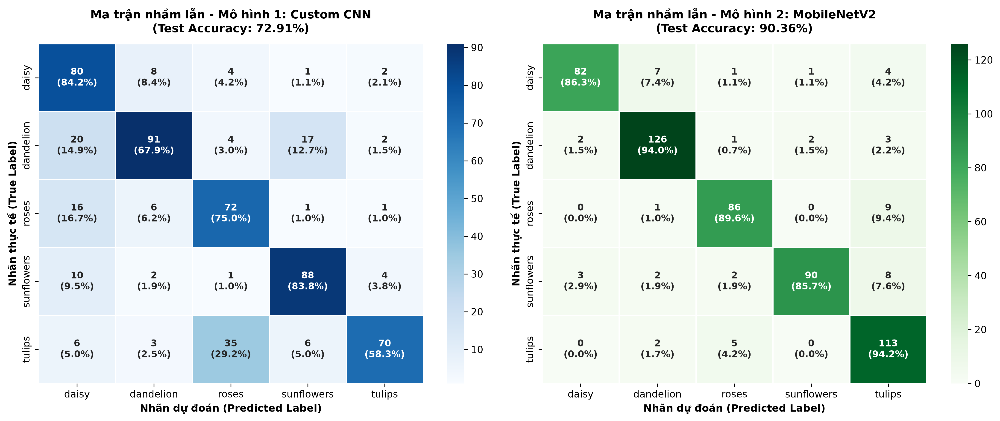

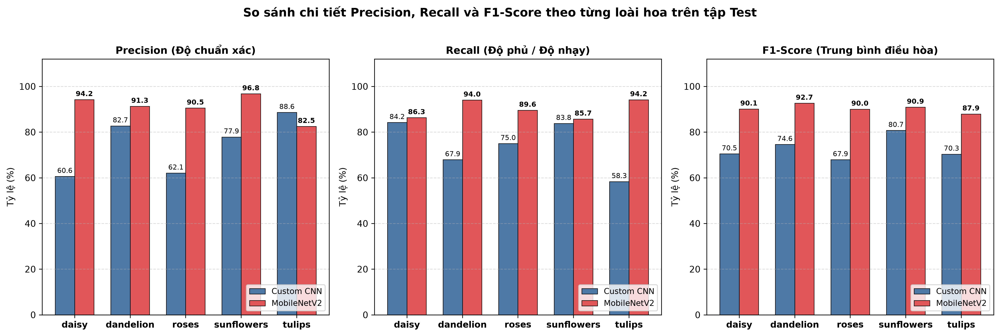

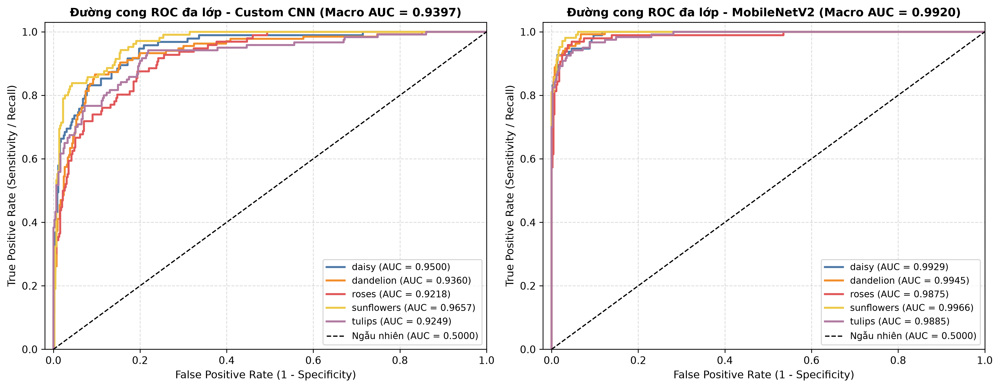

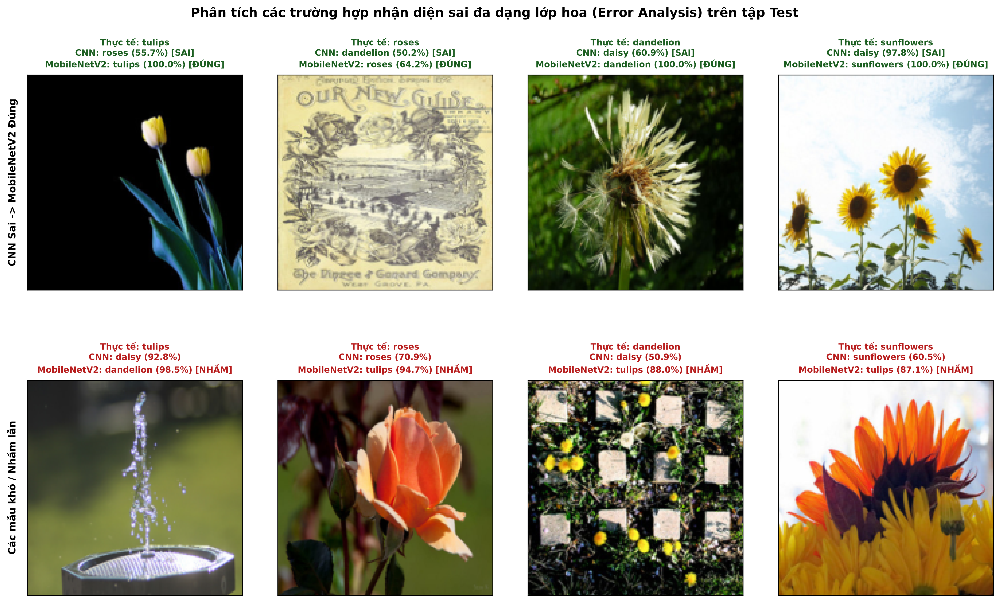

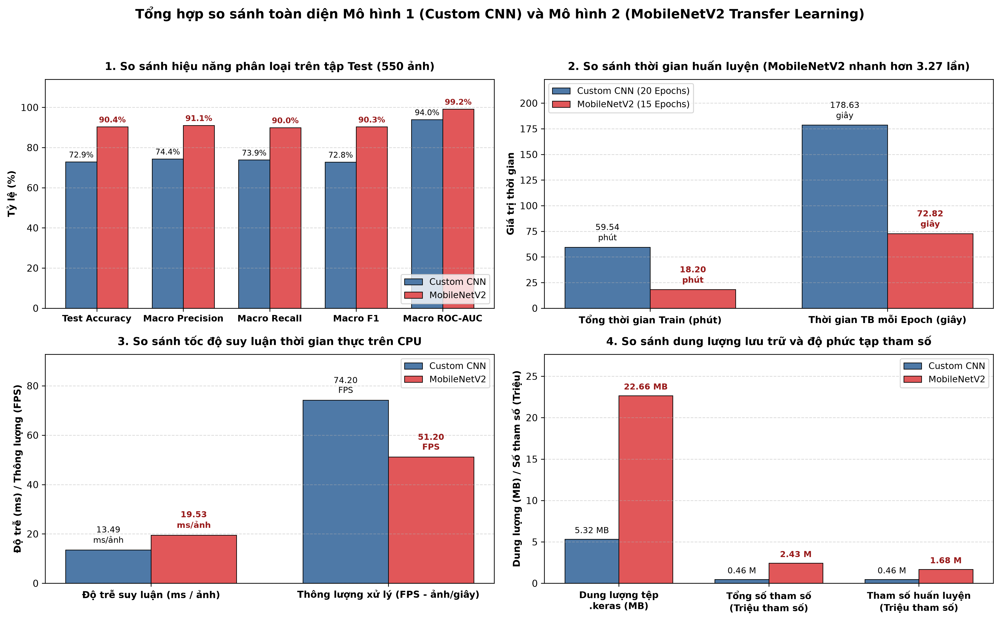

In [7]:
# =============================================================================
# QUY TRÌNH 5: ĐÁNH GIÁ ĐỘC LẬP TRÊN TẬP TEST (550 ẢNH), CONFUSION MATRIX & ROC
# =============================================================================
cnn_best  = tf.keras.models.load_model(cnn_ckpt_path)
mnet_best = tf.keras.models.load_model(mnet_ckpt_path)
X_test_f  = X_test.astype(np.float32)

def evaluate_on_test(model, X_te, y_te, model_label):
    # Warm-up 1 batch nhỏ trước khi đo độ trễ suy luận
    _ = model.predict(X_te[:8], verbose=0)
    t0 = time.perf_counter()
    probs = model.predict(X_te, batch_size=BATCH_SIZE, verbose=0)
    elapsed_ms = (time.perf_counter() - t0) * 1000.0
    ms_per_img = elapsed_ms / len(X_te)
    preds = np.argmax(probs, axis=1)

    acc = accuracy_score(y_te, preds)
    p_m, r_m, f1_m, _ = precision_recall_fscore_support(y_te, preds, average="macro", zero_division=0)
    p_c, r_c, f1_c, sup_c = precision_recall_fscore_support(y_te, preds, average=None, zero_division=0)
    y_bin = label_binarize(y_te, classes=list(range(len(CLASS_NAMES))))
    macro_auc = roc_auc_score(y_bin, probs, average="macro", multi_class="ovr")

    # Khoảng tin cậy 95% Bootstrap CI (1.000 lần lấy mẫu lặp)
    rng = np.random.default_rng(RANDOM_SEED)
    boot_accs = [accuracy_score(y_te[idx], preds[idx]) for idx in (rng.integers(0, len(y_te), len(y_te)) for _ in range(1000))]
    ci_low, ci_high = np.percentile(boot_accs, [2.5, 97.5])

    print(f"  - {model_label:<22}: Test Acc = {acc*100:.2f}% (95% CI: [{ci_low*100:.2f}%, {ci_high*100:.2f}%]) | "
          f"Macro F1 = {f1_m*100:.2f}% | Macro AUC = {macro_auc:.4f} | Latency = {ms_per_img:.2f} ms/ảnh ({1000/ms_per_img:.1f} FPS)")
    return {
        "probs": probs, "preds": preds, "acc": acc, "macro_f1": f1_m, "macro_auc": macro_auc,
        "cm": confusion_matrix(y_te, preds), "per_class_f1": f1_c, "ms_per_img": ms_per_img, "y_bin": y_bin
    }

print(f"[Quy trình 5] Kết quả đánh giá trên tập Test độc lập ({len(y_test)} ảnh):")
res_cnn  = evaluate_on_test(cnn_best,  X_test_f, y_test, "Mô hình 1 (Custom CNN)")
res_mnet = evaluate_on_test(mnet_best, X_test_f, y_test, "Mô hình 2 (MobileNetV2)")

# Vẽ Ma trận nhầm lẫn (Confusion Matrix) đặt cạnh nhau
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.6), dpi=160)
for ax, res, title, cmap in [
    (ax1, res_cnn,  f"Custom CNN (Test Acc: {res_cnn['acc']*100:.2f}%)", "Blues"),
    (ax2, res_mnet, f"MobileNetV2 (Test Acc: {res_mnet['acc']*100:.2f}%)", "Greens"),
]:
    sns.heatmap(res["cm"], annot=True, fmt="d", cmap=cmap, xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=ax, cbar=False)
    ax.set_title(title, fontsize=12, fontweight="bold"); ax.set_xlabel("Nhãn dự đoán"); ax.set_ylabel("Nhãn thực tế")
plt.tight_layout(); plt.show()

# Vẽ đường cong ROC đa lớp (One-vs-Rest)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.2), dpi=160)
for ax, res, title in [(ax1, res_cnn, "ROC Curves - Custom CNN"), (ax2, res_mnet, "ROC Curves - MobileNetV2")]:
    for idx, (cname, col) in enumerate(zip(CLASS_NAMES, CLASS_COLORS)):
        fpr, tpr, _ = roc_curve(res["y_bin"][:, idx], res["probs"][:, idx])
        ax.plot(fpr, tpr, color=col, lw=2, label=f"{cname} (AUC={auc(fpr, tpr):.4f})")
    ax.plot([0, 1], [0, 1], "k--", lw=1)
    ax.set_title(f"{title} (Macro AUC={res['macro_auc']:.4f})", fontweight="bold")
    ax.set_xlabel("False Positive Rate"); ax.set_ylabel("True Positive Rate"); ax.legend(fontsize=8.5); ax.grid(True, linestyle="--", alpha=0.4)
plt.tight_layout(); plt.show()

## 6. DEMO CHỨC NĂNG NHẬP ẢNH HOA MỚI VÀ DỰ ĐOÁN LOÀI HOA CÙNG XÁC SUẤT
Ô code bên dưới cho phép truyền bất kỳ đường dẫn ảnh hoa nào (hoặc upload trực tiếp ảnh từ máy tính nếu chạy trên Google Colab) để xem ngay kết quả dự đoán và xác suất 5 lớp của cả **Custom CNN** và **MobileNetV2**.

Ảnh kiểm thử : 1008566138_6927679c8a.jpg (500x330 px)
  [Custom CNN]  -> Hoa Hướng Dương (Sunflowers) (77.52% | 114.5 ms)
  [MobileNetV2] -> Hoa Hướng Dương (Sunflowers) (100.00% | 121.9 ms)


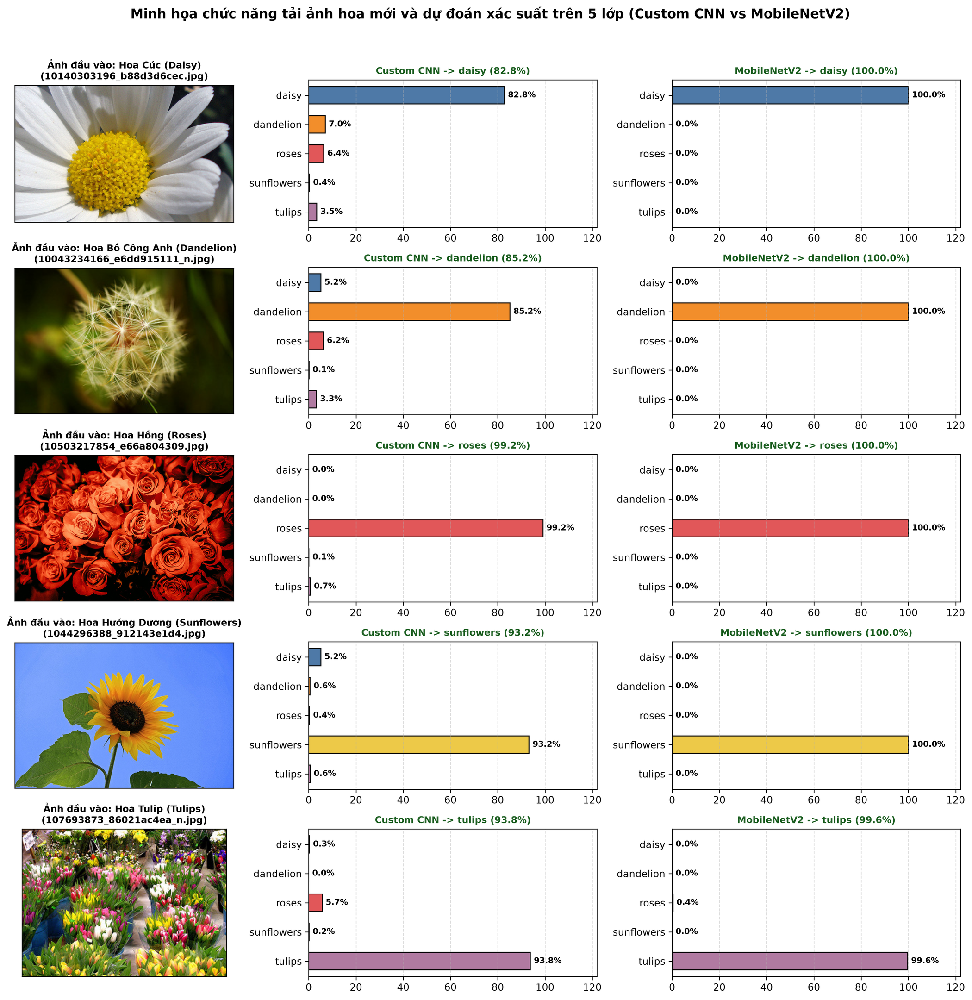

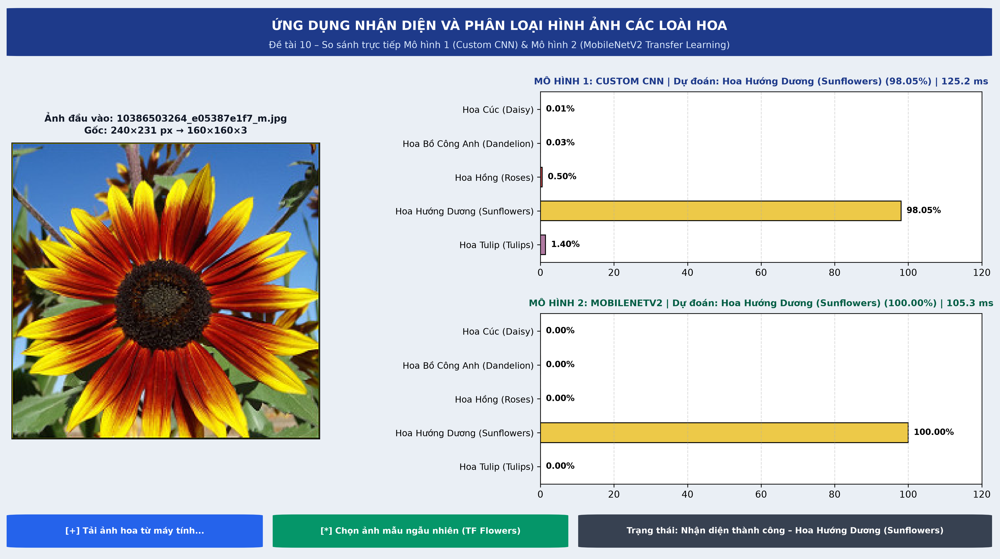

In [8]:
# =============================================================================
# CHỨC NĂNG DỰ ĐOÁN TRỰC TIẾP 1 HÌNH ẢNH HOA MỚI (HỖ TRỢ LOCAL & GOOGLE COLAB)
# =============================================================================
def predict_single_flower(image_path, cnn_model, mnet_model):
    """Tiền xử lý 1 ảnh hoa bất kỳ, dự đoán bằng cả 2 mô hình và vẽ biểu đồ xác suất 5 lớp."""
    with Image.open(image_path) as im:
        rgb = im.convert("RGB")
        orig_w, orig_h = rgb.size
        arr = np.asarray(rgb.resize(IMG_SIZE, Image.Resampling.BILINEAR), dtype=np.float32)

    batch = np.expand_dims(arr, axis=0)
    t0 = time.perf_counter(); p_cnn = cnn_model.predict(batch, verbose=0)[0]; t_cnn = (time.perf_counter() - t0) * 1000
    t1 = time.perf_counter(); p_mnet = mnet_model.predict(batch, verbose=0)[0]; t_mnet = (time.perf_counter() - t1) * 1000

    i_cnn, i_mnet = int(np.argmax(p_cnn)), int(np.argmax(p_mnet))
    print(f"Ảnh kiểm thử : {os.path.basename(image_path)} ({orig_w}x{orig_h} px)")
    print(f"  [Custom CNN]  -> {CLASS_NAMES_VI[CLASS_NAMES[i_cnn]]} ({p_cnn[i_cnn]*100:.2f}% | {t_cnn:.1f} ms)")
    print(f"  [MobileNetV2] -> {CLASS_NAMES_VI[CLASS_NAMES[i_mnet]]} ({p_mnet[i_mnet]*100:.2f}% | {t_mnet:.1f} ms)")

    fig, axes = plt.subplots(1, 3, figsize=(14, 3.8), dpi=150, gridspec_kw={"width_ratios": [1.0, 1.35, 1.35]})
    axes[0].imshow(rgb); axes[0].set_title(f"Ảnh đầu vào\n{os.path.basename(image_path)}", fontweight="bold"); axes[0].axis("off")

    for ax, probs, title in [
        (axes[1], p_cnn,  f"Custom CNN: {CLASS_NAMES[i_cnn]} ({p_cnn[i_cnn]*100:.1f}%)"),
        (axes[2], p_mnet, f"MobileNetV2: {CLASS_NAMES[i_mnet]} ({p_mnet[i_mnet]*100:.1f}%)"),
    ]:
        bars = ax.barh(CLASS_NAMES, probs * 100, color=CLASS_COLORS, edgecolor="black", height=0.6)
        ax.set_xlim(0, 120); ax.invert_yaxis(); ax.set_title(title, fontweight="bold")
        for b, v in zip(bars, probs * 100):
            ax.text(v + 1.5, b.get_y() + b.get_height()/2, f"{v:.1f}%", va="center", fontsize=8.5, fontweight="bold")
        ax.grid(axis="x", linestyle="--", alpha=0.4)
    plt.tight_layout(); plt.show()


# Chạy thử trên 1 ảnh hoa thực tế (có thể đổi sang bất kỳ đường dẫn ảnh hoa nào trên máy)
# Nếu chạy trên Google Colab, bỏ ghi chú 2 dòng dưới để tải ảnh trực tiếp từ máy tính:
# from google.colab import files
# sample_img_path = next(iter(files.upload().keys()))
sample_img_path = os.path.join(DATA_DIR, "sunflowers", "1008566138_6927679c8a.jpg")
predict_single_flower(sample_img_path, cnn_best, mnet_best)

### Tổng kết và Kết luận Thực nghiệm
1. **Về độ chính xác phân loại:** Mô hình **MobileNetV2 (Transfer Learning + Fine-Tuning 30 lớp cuối)** đạt độ chính xác trên tập Test độc lập là **90.36%** (95% CI: `[87.81%, 92.73%]`, Macro F1 = **90.33%**, Macro ROC-AUC = **0.9920**), vượt trội rõ rệt (**+17.45%** Accuracy) so với **Custom CNN** huấn luyện từ đầu (**72.91%**, Macro F1 = **72.82%**, Macro ROC-AUC = **0.9397**).
2. **Về tốc độ & dung lượng triển khai:** Cả hai mô hình đều đáp ứng suy luận thời gian thực trên CPU (**Custom CNN:** `13,49 ms/ảnh` – `74,2 FPS`, `5,32 MB`; **MobileNetV2:** `19,53 ms/ảnh` – `51,2 FPS`, `22,66 MB`).
3. **Khuyến nghị triển khai & Hướng mở rộng:** Chọn **MobileNetV2** làm mô hình lõi cho ứng dụng nhận diện hoa thực tế (`app_nhan_dien_hoa.py`); hướng phát triển tiếp theo gồm mở rộng sang Oxford 102 Flowers, kết hợp YOLO để khoanh vùng nhiều bông hoa trong cùng ảnh, lượng tử hóa sang TensorFlow Lite (`INT8/FP16`) cho di động và tích hợp bản đồ nhiệt giải thích **Grad-CAM**.